# 🍽️ Task 1: Top Cuisines

In [1]:
import pandas as pd

# Load your dataset
df = pd.read_csv("Dataset.csv")

# Show first few rows
df.head()


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [5]:
# Check column names
df.columns

# Drop rows where cuisine info is missing
df = df.dropna(subset=['Cuisines'])

In [7]:
# Split the cuisines and count frequency
from collections import Counter

cuisine_counts = Counter()

for cuisines in df['Cuisines']:
    for cuisine in str(cuisines).split(','):
        cuisine_counts[cuisine.strip()] += 1

# Convert to a DataFrame
cuisine_df = pd.DataFrame(cuisine_counts.items(), columns=['Cuisine', 'Count'])

# Sort and get top 3
top3 = cuisine_df.sort_values(by='Count', ascending=False).head(3)
top3

,Cuisine,Count
81,North Indian,3960
9,Chinese,2735
19,Fast Food,1986


In [9]:
total_restaurants = len(df)
top3['Percentage'] = (top3['Count'] / total_restaurants) * 100
top3

,Cuisine,Count,Percentage
81,North Indian,3960,41.500734
9,Chinese,2735,28.662754
19,Fast Food,1986,20.813247


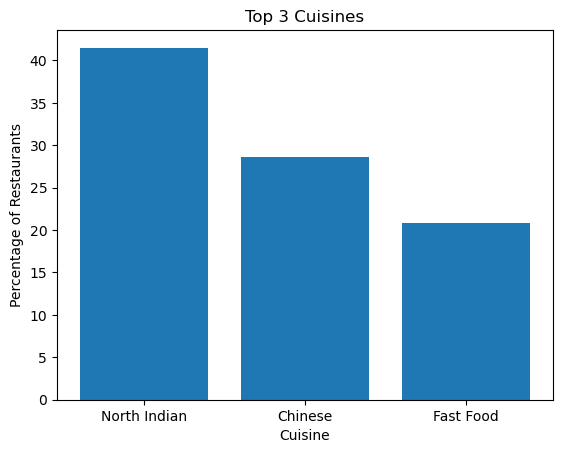

In [11]:
import matplotlib.pyplot as plt

plt.bar(top3['Cuisine'], top3['Percentage'])
plt.title('Top 3 Cuisines')
plt.xlabel('Cuisine')
plt.ylabel('Percentage of Restaurants')
plt.show()

In [13]:
top3.to_csv("Top3_Cuisines.csv", index=False)

# 🏙️ Task 2: City Analysis

In [17]:
import pandas as pd
df = pd.read_csv("Dataset.csv")

In [19]:
df.columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='object')

In [21]:
city_counts = df['City'].value_counts()
top_city = city_counts.idxmax()
top_city_count = city_counts.max()

print("City with the highest number of restaurants:", top_city)
print("Number of restaurants:", top_city_count)

City with the highest number of restaurants: New Delhi
Number of restaurants: 5473


In [23]:
city_avg_rating = df.groupby('City')['Aggregate rating'].mean().sort_values(ascending=False)
city_avg_rating.head()

City
Inner City          4.900000
Quezon City         4.800000
Makati City         4.650000
Pasig City          4.633333
Mandaluyong City    4.625000
Name: Aggregate rating, dtype: float64

In [25]:
top_rated_city = city_avg_rating.idxmax()
top_rated_value = city_avg_rating.max()

print("City with the highest average rating:", top_rated_city)
print("Average Rating:", round(top_rated_value, 2))

City with the highest average rating: Inner City
Average Rating: 4.9


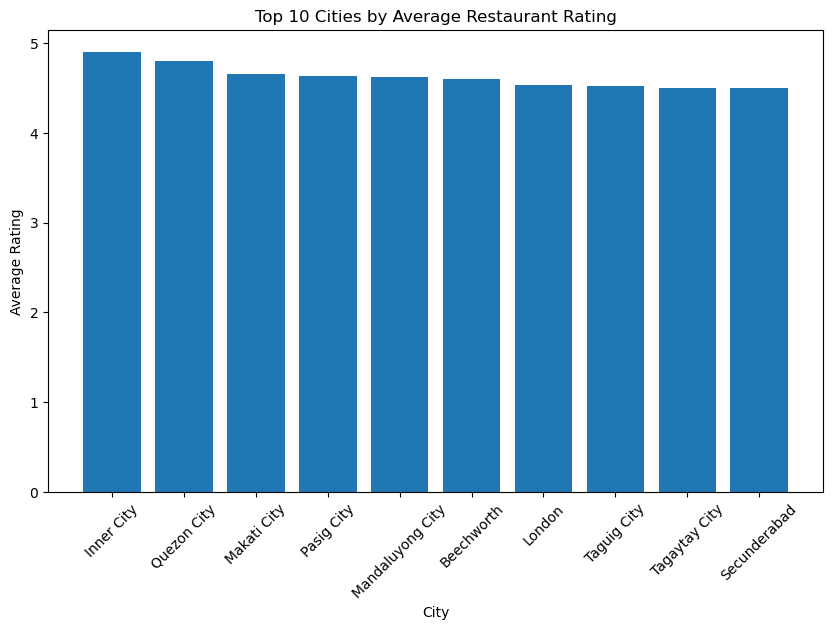

In [27]:
import matplotlib.pyplot as plt

top10_ratings = city_avg_rating.head(10)

plt.figure(figsize=(10,6))
plt.bar(top10_ratings.index, top10_ratings.values)
plt.title('Top 10 Cities by Average Restaurant Rating')
plt.xlabel('City')
plt.ylabel('Average Rating')
plt.xticks(rotation=45)
plt.show()

In [29]:
# City counts
city_counts_df = city_counts.reset_index()
city_counts_df.columns = ['City', 'Restaurant_Count']
city_counts_df.to_csv("City_Restaurant_Count.csv", index=False)

# Average ratings
city_avg_rating_df = city_avg_rating.reset_index()
city_avg_rating_df.columns = ['City', 'Average_Rating']
city_avg_rating_df.to_csv("City_Average_Rating.csv", index=False)

# 💰 Task 3 – Price Range Distribution

In [37]:
import pandas as pd
df = pd.read_csv("Dataset.csv")

In [39]:
df.columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='object')

In [41]:
price_counts = df['Price range'].value_counts().sort_index()

# Convert to percentage
price_percent = (price_counts / len(df)) * 100

price_df = pd.DataFrame({
    'Price Range': price_counts.index,
    'Count': price_counts.values,
    'Percentage': price_percent.values
})

price_df

,Price Range,Count,Percentage
0,1,4444,46.529159
1,2,3113,32.593446
2,3,1408,14.741912
3,4,586,6.135483


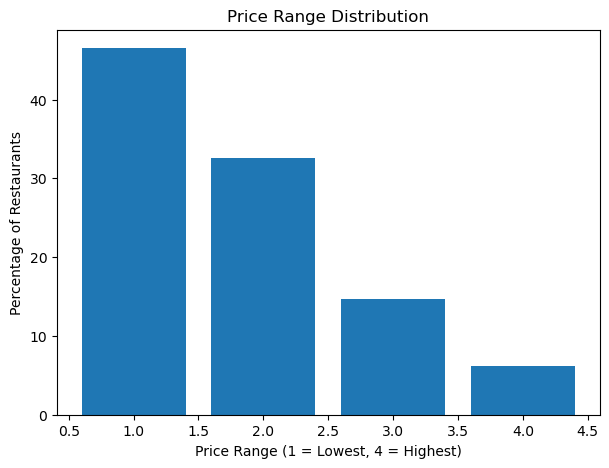

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))
plt.bar(price_df['Price Range'], price_df['Percentage'])
plt.title('Price Range Distribution')
plt.xlabel('Price Range (1 = Lowest, 4 = Highest)')
plt.ylabel('Percentage of Restaurants')
plt.show()

In [45]:
plt.savefig("Price_Range_Distribution.png")

<Figure size 640x480 with 0 Axes>

In [47]:
price_df.to_csv("Price_Range_Distribution.csv", index=False)

# 📦 Task 4 – Online Delivery

In [50]:
import pandas as pd
df = pd.read_csv("Dataset.csv")

In [52]:
df.columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='object')

In [54]:
online_delivery_counts = df['Has Online delivery'].value_counts()
delivery_percent = (online_delivery_counts / len(df)) * 100

print("Online delivery distribution:\n", delivery_percent)

Online delivery distribution:
 Has Online delivery
No     74.337766
Yes    25.662234
Name: count, dtype: float64


In [58]:
avg_rating_delivery = df.groupby('Has Online delivery')['Aggregate rating'].mean()
avg_rating_delivery

Has Online delivery
No     2.465296
Yes    3.248837
Name: Aggregate rating, dtype: float64

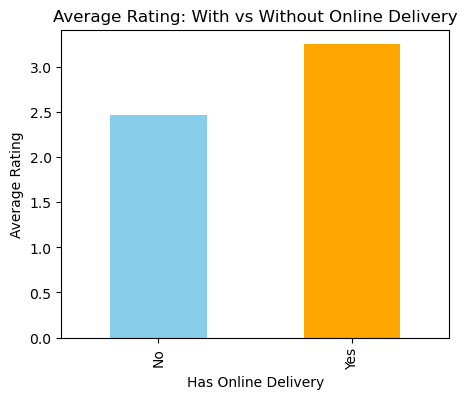

In [60]:
plt.figure(figsize=(5,4))
avg_rating_delivery.plot(kind='bar', color=['skyblue','orange'])
plt.title('Average Rating: With vs Without Online Delivery')
plt.xlabel('Has Online Delivery')
plt.ylabel('Average Rating')
plt.show()

In [62]:
plt.savefig("Online_Delivery_Rating_Comparison.png")

<Figure size 640x480 with 0 Axes>

In [64]:
avg_rating_delivery_df = avg_rating_delivery.reset_index()
avg_rating_delivery_df.columns = ['Has_Online_Delivery', 'Average_Rating']
avg_rating_delivery_df.to_csv("Online_Delivery_Rating.csv", index=False)